## ACCESS THE DATA

In [5]:
import pandas as pd
import numpy as np
dataset=pd.read_csv("Salary_Data.csv")
print(dataset.head(8))


   YearsExperience   Salary
0              1.1  39343.0
1              1.3  46205.0
2              1.5  37731.0
3              2.0  43525.0
4              2.2  39891.0
5              2.9  56642.0
6              3.0  60150.0
7              3.2  54445.0


## Step-02 check if data is null or not

In [7]:
print(dataset.isnull().sum())

YearsExperience    0
Salary             0
dtype: int64


## Get the X axis data and Yaxis data

In [9]:
import matplotlib.pyplot as plt
X=dataset.iloc[:,:-1];
Y=dataset.iloc[:,-1];
print(X.head())
print(Y.head())


   YearsExperience
0              1.1
1              1.3
2              1.5
3              2.0
4              2.2
0    39343.0
1    46205.0
2    37731.0
3    43525.0
4    39891.0
Name: Salary, dtype: float64


## PLOT TO CHECK LINEARITY

Text(0.5, 1.0, 'Scatter plot salary and year of experience')

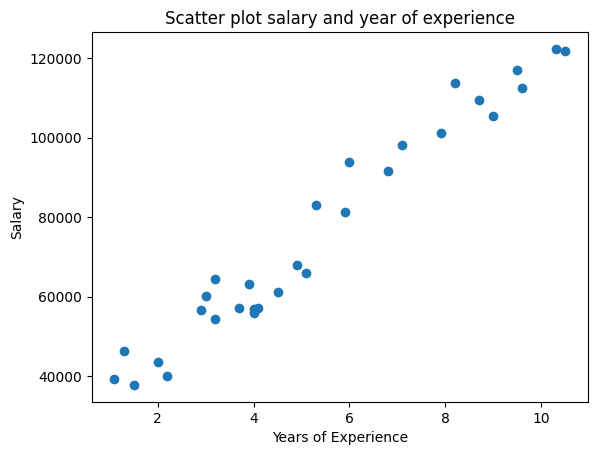

In [12]:
plt.scatter(X,Y)
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Scatter plot salary and year of experience")

## Split data into training and testing data

In [24]:
from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest=train_test_split(X,Y,test_size=0.2,random_state=42)

print("training data")
print(xtrain.head(10),ytrain.head(10))

training data
    YearsExperience
28             10.3
24              8.7
12              4.0
0               1.1
4               2.2
16              5.1
5               2.9
13              4.1
11              4.0
22              7.9 28    122391.0
24    109431.0
12     56957.0
0      39343.0
4      39891.0
16     66029.0
5      56642.0
13     57081.0
11     55794.0
22    101302.0
Name: Salary, dtype: float64


## training the model 

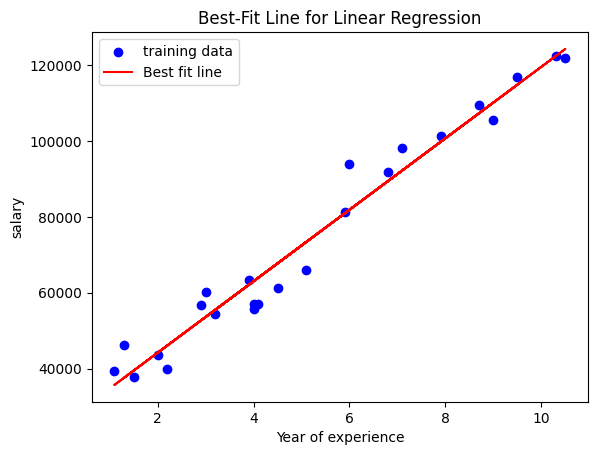

In [29]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(xtrain,ytrain)
plt.scatter(xtrain,ytrain,color='blue',label='training data')
plt.plot(xtrain,model.predict(xtrain),color='red',label='Best fit line')
plt.xlabel('Year of experience')
plt.ylabel('salary')
plt.title('Best-Fit Line for Linear Regression')
plt.legend()



## predicting the salary using texting data of years of experience

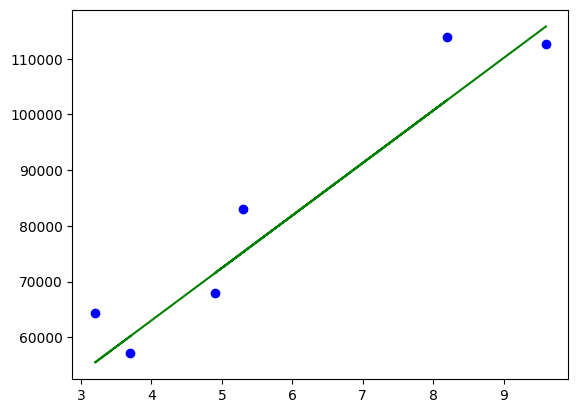

In [28]:
plt.scatter(xtest,ytest,color='blue',label='training data')
ypred=model.predict(xtest)
plt.plot(xtest,ypred,color='green')

## Evaluating the predicted values

In [37]:
from sklearn.metrics import mean_squared_error,r2_score
mse=mean_squared_error(ytest,ypred)
r2=r2_score(ytest,ypred)
print("MSE: ",np.sqrt(mse))
print("R2: ",r2)
# Calculate standard deviation of salaries
salary_std = np.std(ytrain)
print(f"Standard Deviation of Salaries: {salary_std:.2f}")

MSE:  7059.04362190151
R2:  0.9024461774180497
Standard Deviation of Salaries: 27646.13


In [39]:
new_data=pd.DataFrame({
    'YearsExperience':[3,4,5,6,7]
})
predictedSalaries=model.predict(new_data)
print("Predicted Salaries:")
print(predictedSalaries)

Predicted Salaries:
[53593.02898087 63016.8443039  72440.65962693 81864.47494996
 91288.29027299]


## exporting te model using joblib

In [42]:
import joblib
joblib.dump(model,'Sp.pkl')

['Sp.pkl']